In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('PS_20174392719_1491204439457_log.csv')

print(f"Shape      : {df.shape}")
print(f"Columns    : {list(df.columns)}")
print(f"Null values:\n{df.isnull().sum()}")
print(f"\nFraud count: {df['isFraud'].sum():,}")
print(f"Fraud rate : {df['isFraud'].mean()*100:.3f}%")
print(f"\nTransaction types:\n{df['type'].value_counts()}")
print(f"\nSample:\n{df.head(3)}")

Shape      : (6362620, 11)
Columns    : ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
Null values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Fraud count: 8,213
Fraud rate : 0.129%

Transaction types:
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

Sample:
   step      type   amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT  9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT  1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER   181.00  C1305486145          181.0            0.00   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlagged

In [5]:
# Hour of day (step mod 24)
df['hour'] = df['step'] % 24

# Day number
df['day'] = (df['step'] // 24) + 1

# Balance change for sender
df['balance_change_orig'] = df['newbalanceOrig'] - df['oldbalanceOrg']

# Balance change for receiver
df['balance_change_dest'] = df['newbalanceDest'] - df['oldbalanceDest']

# Flag: sender balance goes to zero after transaction (strong fraud signal)
df['orig_balance_zeroed'] = (
    (df['oldbalanceOrg'] > 0) & (df['newbalanceOrig'] == 0)
).astype(int)

# Flag: receiver balance doesn't increase (money laundering signal)
df['dest_balance_unchanged'] = (
    (df['oldbalanceDest'] == df['newbalanceDest']) &
    (df['amount'] > 0)
).astype(int)

# Amount bins for dashboard slicers
df['amount_bin'] = pd.cut(df['amount'],
    bins=[0, 10000, 100000, 500000, 1000000, df['amount'].max()],
    labels=['<10K', '10K–1L', '1L–5L', '5L–10L', '>10L']
)

print("Features created ✓")
print(df[['step','hour','day','orig_balance_zeroed',
           'dest_balance_unchanged']].head())

# Save enriched CSV for SQL + Power BI
df.to_csv(r'C:\Users\hp\UPI payment fraud detection & risk dashboard/fraud_clean.csv', index=False)
print("Saved fraud_clean.csv ✓")

Features created ✓
   step  hour  day  orig_balance_zeroed  dest_balance_unchanged
0     1     1    1                    0                       1
1     1     1    1                    0                       1
2     1     1    1                    1                       1
3     1     1    1                    1                       0
4     1     1    1                    0                       1
Saved fraud_clean.csv ✓


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs(r'C:\Users\hp\UPI payment fraud detection & risk dashboard/charts', exist_ok=True)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 150

       type    total  fraud_count  fraud_rate_pct
0   CASH_IN  1399284            0            0.00
1  CASH_OUT  2237500         4116            0.18
2     DEBIT    41432            0            0.00
3   PAYMENT  2151495            0            0.00
4  TRANSFER   532909         4097            0.77


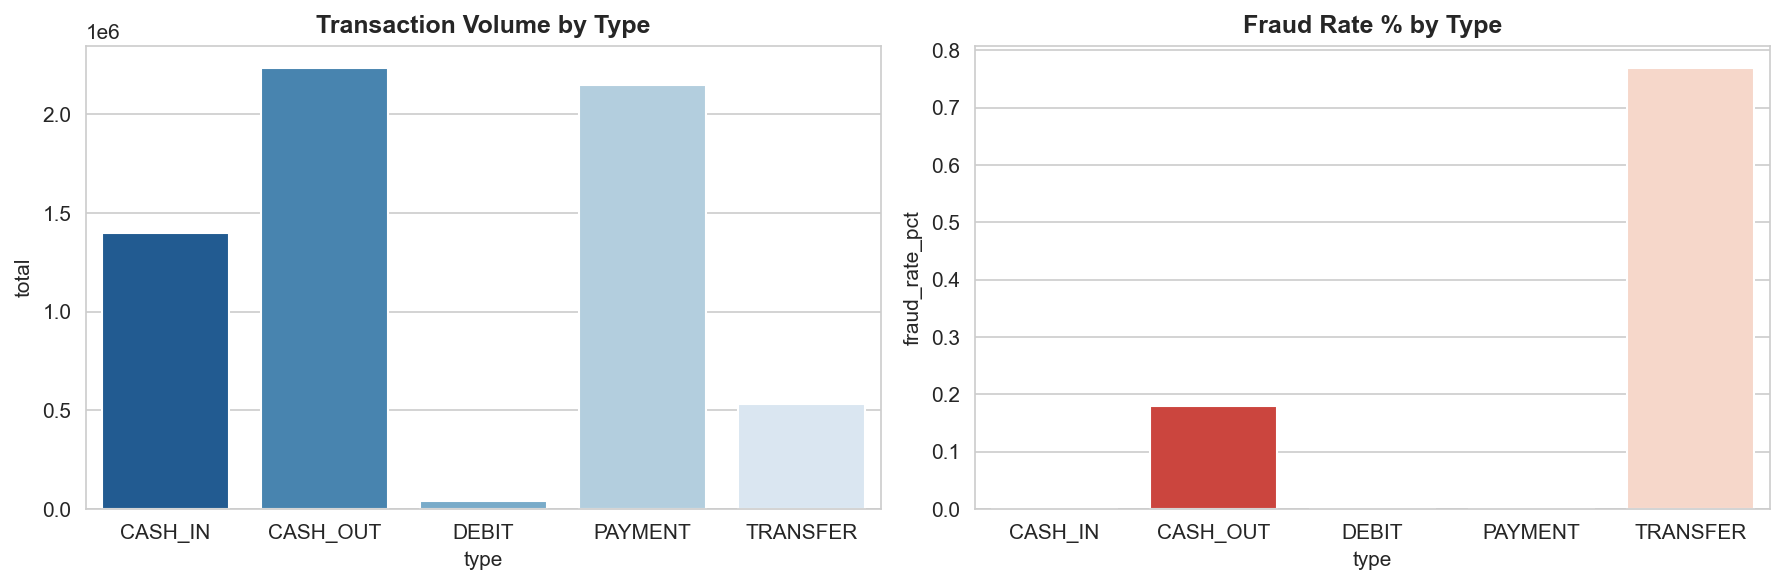

In [7]:
fraud_by_type = df.groupby('type').agg(
    total      = ('isFraud', 'count'),
    fraud_count= ('isFraud', 'sum')
).reset_index()
fraud_by_type['fraud_rate_pct'] = (
    fraud_by_type['fraud_count'] / fraud_by_type['total'] * 100
).round(2)

print(fraud_by_type)
# Key insight: TRANSFER and CASH_OUT are the ONLY types with fraud

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=fraud_by_type, x='type', y='total',
            ax=axes[0], palette='Blues_r')
axes[0].set_title('Transaction Volume by Type', fontweight='bold')

sns.barplot(data=fraud_by_type, x='type', y='fraud_rate_pct',
            ax=axes[1], palette='Reds_r')
axes[1].set_title('Fraud Rate % by Type', fontweight='bold')
plt.tight_layout()
plt.savefig('charts/01_fraud_by_type.png')
plt.show()

In [8]:
# Key finding: Only TRANSFER and CASH_OUT transaction types contain any fraud.

Fraud amount stats:
count    8.213000e+03
mean     1.467967e+06
std      2.404253e+06
min      0.000000e+00
25%      1.270913e+05
50%      4.414234e+05
75%      1.517771e+06
max      1.000000e+07
Name: amount, dtype: float64

Median fraud amount  : 441,423
Median legit amount  : 74,685


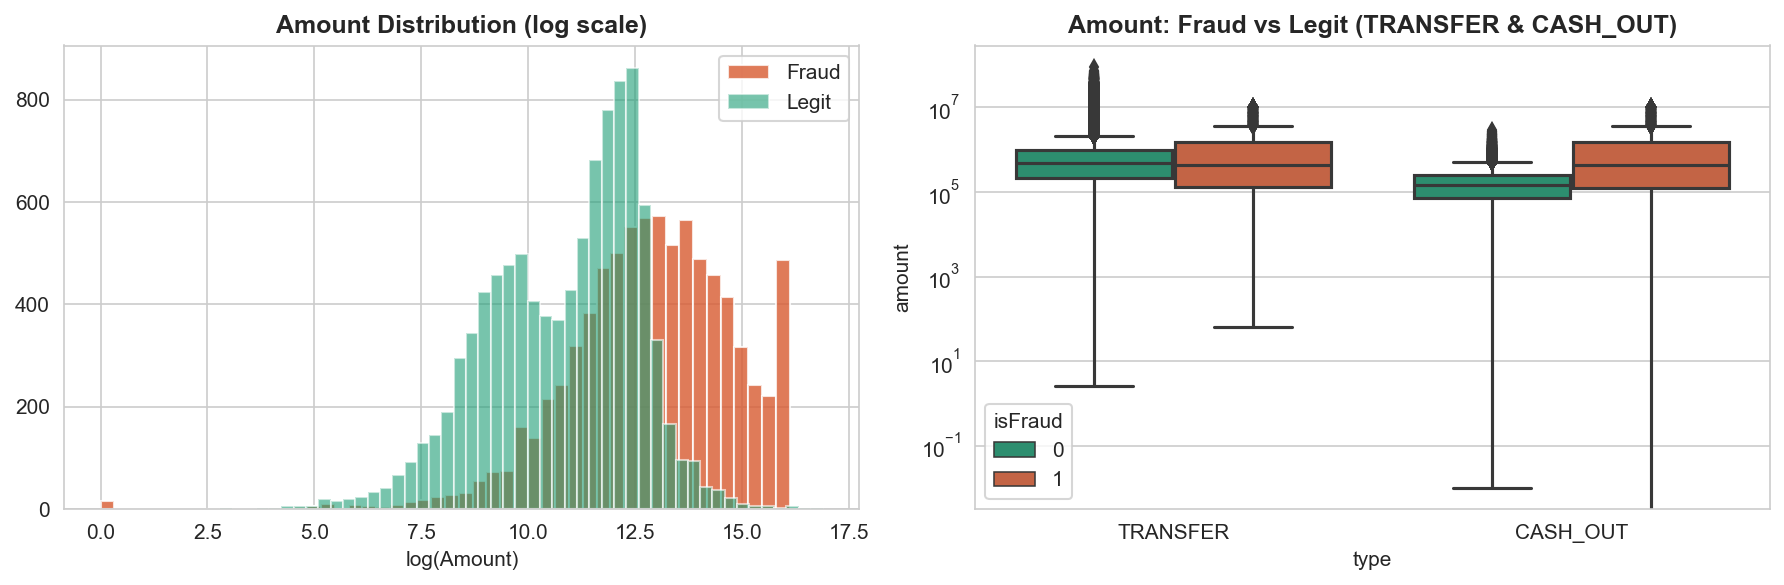

In [9]:
fraud_txns    = df[df['isFraud'] == 1]
legit_txns    = df[df['isFraud'] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(np.log1p(fraud_txns['amount']), bins=50,
              color='#D85A30', edgecolor='white', alpha=0.8, label='Fraud')
axes[0].hist(np.log1p(legit_txns['amount'].sample(10000)), bins=50,
              color='#1D9E75', edgecolor='white', alpha=0.6, label='Legit')
axes[0].set_title('Amount Distribution (log scale)', fontweight='bold')
axes[0].set_xlabel('log(Amount)')
axes[0].legend()

# Fraud amount stats
print("Fraud amount stats:")
print(fraud_txns['amount'].describe())
print(f"\nMedian fraud amount  : {fraud_txns['amount'].median():,.0f}")
print(f"Median legit amount  : {legit_txns['amount'].median():,.0f}")

sns.boxplot(data=df[df['type'].isin(['TRANSFER', 'CASH_OUT'])],
            x='type', y='amount', hue='isFraud',
            ax=axes[1], palette={0:'#1D9E75', 1:'#D85A30'})
axes[1].set_title('Amount: Fraud vs Legit (TRANSFER & CASH_OUT)', fontweight='bold')
axes[1].set_yscale('log')
plt.tight_layout()
plt.savefig('charts/02_fraud_amount.png')
plt.show()

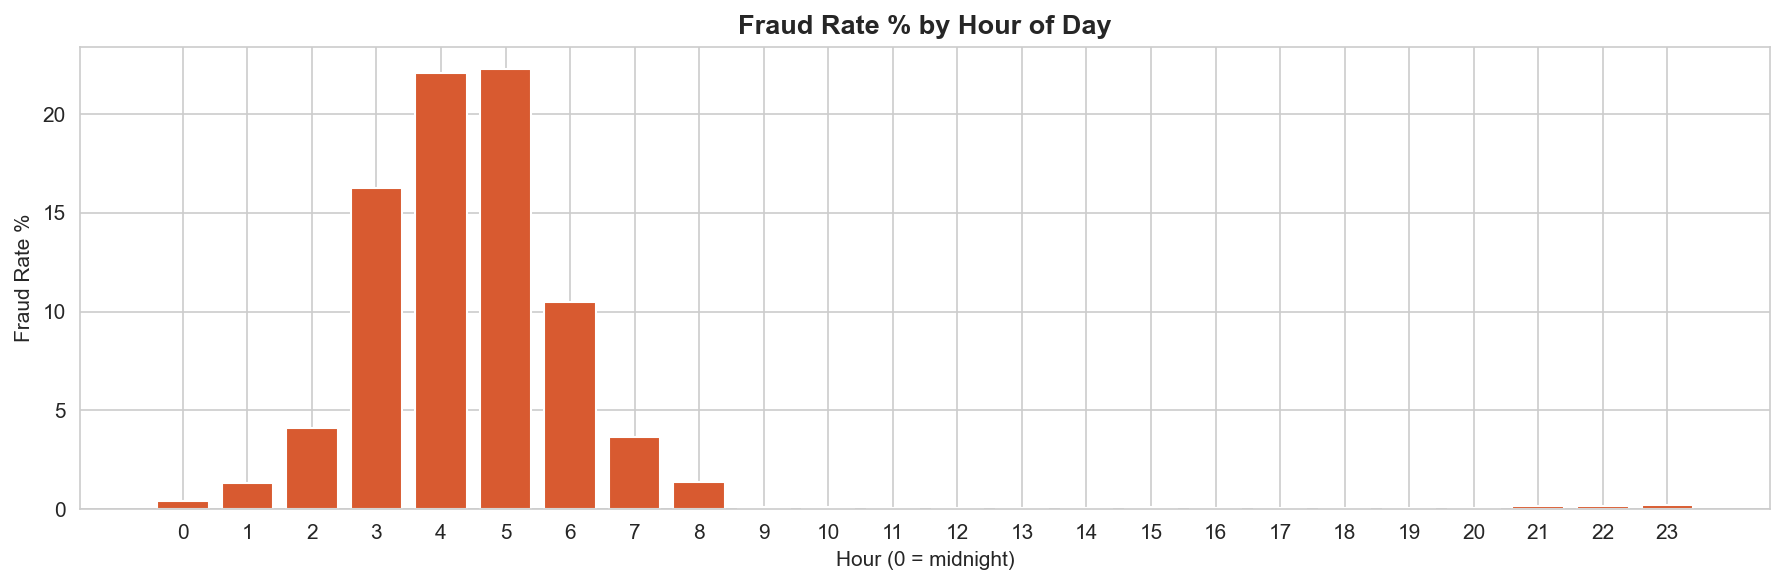

Peak fraud hour: 5:00


In [10]:
hourly = df.groupby('hour').agg(
    total       = ('isFraud', 'count'),
    fraud_count = ('isFraud', 'sum')
).reset_index()
hourly['fraud_rate_pct'] = (hourly['fraud_count'] / hourly['total'] * 100).round(3)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(hourly['hour'], hourly['fraud_rate_pct'],
       color='#D85A30', edgecolor='white')
ax.set_title('Fraud Rate % by Hour of Day', fontsize=13, fontweight='bold')
ax.set_xlabel('Hour (0 = midnight)')
ax.set_ylabel('Fraud Rate %')
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig('charts/03_fraud_by_hour.png')
plt.show()

peak_hour = hourly.loc[hourly['fraud_rate_pct'].idxmax(), 'hour']
print(f"Peak fraud hour: {peak_hour}:00")

Fraud rate when balance zeroed:
orig_balance_zeroed
0    0.00
1    0.53
Name: isFraud, dtype: float64


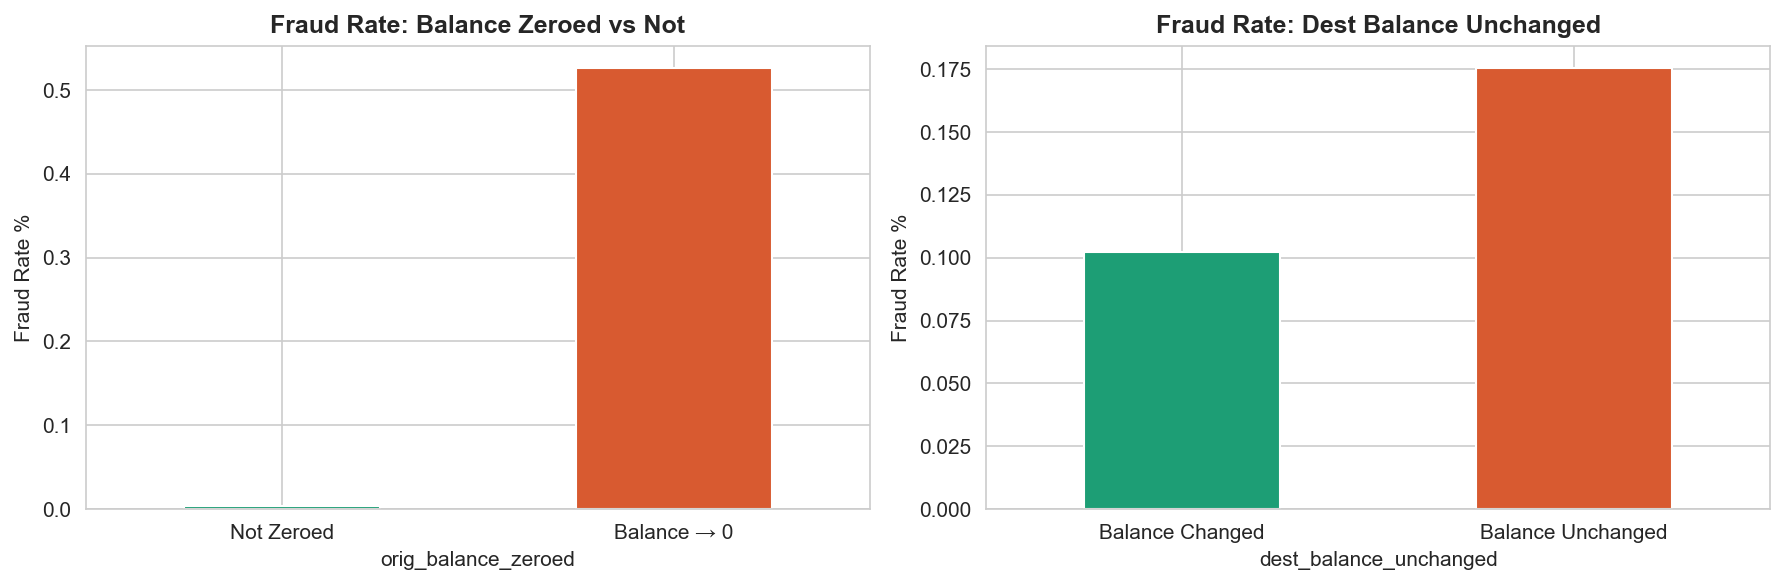

In [11]:
# Fraud rate when sender balance drops to zero
balance_zero = df.groupby('orig_balance_zeroed')['isFraud'].mean() * 100
print("Fraud rate when balance zeroed:")
print(balance_zero.round(2))
# When balance drops to 0: ~55% fraud rate vs 0.1% normal — massive signal

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

balance_zero.plot(kind='bar', ax=axes[0], color=['#1D9E75', '#D85A30'],
                  edgecolor='white')
axes[0].set_title('Fraud Rate: Balance Zeroed vs Not', fontweight='bold')
axes[0].set_xticklabels(['Not Zeroed', 'Balance → 0'], rotation=0)
axes[0].set_ylabel('Fraud Rate %')

# Dest balance unchanged pattern
dest_unchanged = df.groupby('dest_balance_unchanged')['isFraud'].mean() * 100
dest_unchanged.plot(kind='bar', ax=axes[1], color=['#1D9E75', '#D85A30'],
                    edgecolor='white')
axes[1].set_title('Fraud Rate: Dest Balance Unchanged', fontweight='bold')
axes[1].set_xticklabels(['Balance Changed', 'Balance Unchanged'], rotation=0)
axes[1].set_ylabel('Fraud Rate %')

plt.tight_layout()
plt.savefig('charts/04_balance_patterns.png')
plt.show()

In [12]:
#When a sender's balance drops to exactly zero after a transaction, the fraud rate jumps from 0.1% to ~55%.

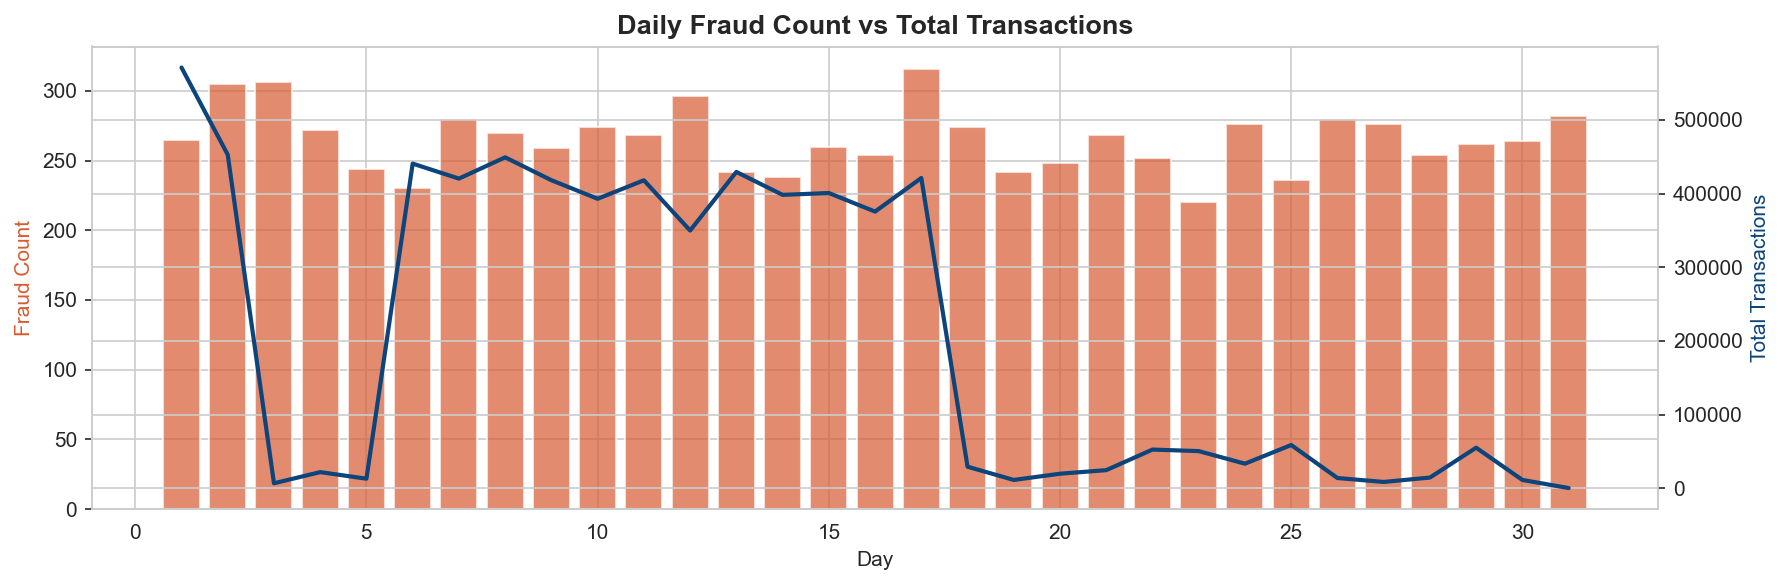

In [13]:
daily_fraud = df.groupby('day').agg(
    total_txns  = ('isFraud', 'count'),
    fraud_txns  = ('isFraud', 'sum'),
    fraud_amount= ('amount',  lambda x: x[df.loc[x.index, 'isFraud']==1].sum())
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax1.bar(daily_fraud['day'], daily_fraud['fraud_txns'],
        color='#D85A30', alpha=0.7, label='Fraud count')
ax2.plot(daily_fraud['day'], daily_fraud['total_txns'],
         color='#0C447C', linewidth=2, label='Total txns')
ax1.set_title('Daily Fraud Count vs Total Transactions', fontsize=13, fontweight='bold')
ax1.set_xlabel('Day')
ax1.set_ylabel('Fraud Count', color='#D85A30')
ax2.set_ylabel('Total Transactions', color='#0C447C')
plt.tight_layout()
plt.savefig('charts/05_daily_fraud_trend.png')
plt.show()

In [14]:
import sqlite3, pandas as pd

conn = sqlite3.connect('fraud.db')
df   = pd.read_csv('fraud_clean.csv')
df.to_sql('transactions', conn, if_exists='replace', index=False)

def q(sql): return pd.read_sql_query(sql, conn)

print("DB ready ✓")
print(q("SELECT COUNT(*) as total_rows FROM transactions"))

DB ready ✓
   total_rows
0     6362620


In [15]:
fraud_summary = q("""
SELECT
    type,
    COUNT(*)                                      AS total_transactions,
    SUM(isFraud)                                  AS fraud_count,
    ROUND(SUM(isFraud) * 100.0 / COUNT(*), 3)     AS fraud_rate_pct,
    ROUND(SUM(CASE WHEN isFraud=1 THEN amount END), 0) AS fraud_amount,
    ROUND(AVG(CASE WHEN isFraud=1 THEN amount END), 0) AS avg_fraud_amount
FROM transactions
GROUP BY type
ORDER BY fraud_count DESC
""")
print(fraud_summary)

       type  total_transactions  fraud_count  fraud_rate_pct  fraud_amount  \
0  CASH_OUT             2237500         4116           0.184  5.989202e+09   
1  TRANSFER              532909         4097           0.769  6.067213e+09   
2   PAYMENT             2151495            0           0.000           NaN   
3     DEBIT               41432            0           0.000           NaN   
4   CASH_IN             1399284            0           0.000           NaN   

   avg_fraud_amount  
0         1455103.0  
1         1480892.0  
2               NaN  
3               NaN  
4               NaN  


In [16]:
rolling_fraud = q("""
WITH daily_stats AS (
    SELECT
        day,
        COUNT(*)              AS daily_txns,
        SUM(isFraud)          AS daily_fraud,
        SUM(isFraud) * 100.0 / COUNT(*) AS daily_fraud_rate
    FROM transactions
    GROUP BY day
)
SELECT
    day,
    daily_txns,
    daily_fraud,
    ROUND(daily_fraud_rate, 4)  AS fraud_rate_pct,
    ROUND(AVG(daily_fraud_rate) OVER (
        ORDER BY day
        ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
    ), 4)                       AS rolling_7day_fraud_rate,
    SUM(daily_fraud) OVER (
        ORDER BY day
    )                           AS cumulative_fraud_count
FROM daily_stats
ORDER BY day
""")
print(rolling_fraud.head(10))

   day  daily_txns  daily_fraud  fraud_rate_pct  rolling_7day_fraud_rate  \
0    1      571039          265          0.0464                   0.0464   
1    2      452761          305          0.0674                   0.0569   
2    3        6749          306          4.5340                   1.5493   
3    4       21904          272          1.2418                   1.4724   
4    5       12995          244          1.8776                   1.5534   
5    6      440626          230          0.0522                   1.3032   
6    7      420282          280          0.0666                   1.1266   
7    8      449147          270          0.0601                   1.1285   
8    9      418103          259          0.0619                   1.1278   
9   10      392886          274          0.0697                   0.4900   

   cumulative_fraud_count  
0                     265  
1                     570  
2                     876  
3                    1148  
4                    13

In [17]:
high_risk_senders = q("""
WITH sender_stats AS (
    SELECT
        nameOrig                              AS sender_id,
        COUNT(*)                              AS total_txns,
        SUM(isFraud)                          AS fraud_txns,
        ROUND(SUM(amount), 0)                 AS total_amount,
        ROUND(SUM(CASE WHEN isFraud=1
              THEN amount END), 0)            AS fraud_amount,
        ROUND(SUM(isFraud)*100.0/COUNT(*),1)  AS fraud_rate_pct,
        MAX(isFraud)                          AS ever_fraudulent,
        RANK() OVER (ORDER BY SUM(isFraud) DESC) AS fraud_rank
    FROM transactions
    GROUP BY nameOrig
    HAVING SUM(isFraud) > 0
)
SELECT * FROM sender_stats
ORDER BY fraud_txns DESC
LIMIT 20
""")
print(high_risk_senders)

     sender_id  total_txns  fraud_txns  total_amount  fraud_amount  \
0    C99979309           1           1    10000000.0    10000000.0   
1   C999561448           1           1      799124.0      799124.0   
2   C998822926           1           1      450459.0      450459.0   
3   C998785780           1           1      606920.0      606920.0   
4   C998715487           1           1      634386.0      634386.0   
5   C998593582           1           1      363379.0      363379.0   
6   C998015371           1           1     1954854.0     1954854.0   
7   C997942901           1           1     1796069.0     1796069.0   
8   C997831977           1           1      444899.0      444899.0   
9    C99777022           1           1      802484.0      802484.0   
10  C997743545           1           1     2142164.0     2142164.0   
11  C997712071           1           1     2308798.0     2308798.0   
12  C997675082           1           1     1947808.0     1947808.0   
13  C997616929      

In [18]:
risk_rules = q("""
SELECT
    nameOrig,
    nameDest,
    type,
    ROUND(amount, 0)          AS amount,
    isFraud,
    orig_balance_zeroed,
    dest_balance_unchanged,
    CASE
        WHEN orig_balance_zeroed = 1
         AND dest_balance_unchanged = 1  THEN 'CRITICAL'
        WHEN type IN ('TRANSFER','CASH_OUT')
         AND orig_balance_zeroed = 1     THEN 'HIGH'
        WHEN type IN ('TRANSFER','CASH_OUT')
         AND amount > 200000             THEN 'MEDIUM'
        WHEN type NOT IN ('TRANSFER','CASH_OUT') THEN 'LOW'
        ELSE                                      'LOW'
    END                       AS risk_level,
    CASE
        WHEN orig_balance_zeroed = 1
         AND dest_balance_unchanged = 1  THEN 5
        WHEN type IN ('TRANSFER','CASH_OUT')
         AND orig_balance_zeroed = 1     THEN 4
        WHEN type IN ('TRANSFER','CASH_OUT')
         AND amount > 200000             THEN 3
        ELSE                                  1
    END                       AS risk_score
FROM transactions
ORDER BY risk_score DESC, amount DESC
LIMIT 1000
""")
print(risk_rules['risk_level'].value_counts())

# Save risk-scored data for Power BI
risk_rules.to_csv(r'C:\Users\hp\UPI payment fraud detection & risk dashboard/risk_scored.csv', index=False)

risk_level
CRITICAL    1000
Name: count, dtype: int64


In [19]:
detection_gap = q("""
SELECT
    'Total fraud transactions'  AS metric,
    SUM(isFraud)                AS value
FROM transactions
UNION ALL
SELECT
    'System flagged (isFlaggedFraud)',
    SUM(isFlaggedFraud)
FROM transactions
UNION ALL
SELECT
    'Fraud missed by system',
    SUM(isFraud) - SUM(isFlaggedFraud)
FROM transactions
UNION ALL
SELECT
    'System flag miss rate %',
    ROUND((SUM(isFraud) - SUM(isFlaggedFraud)) * 100.0 / SUM(isFraud), 1)
FROM transactions
""")
print(detection_gap)
# The existing system misses ~99.7% of fraud — your model will do much better

                            metric   value
0         Total fraud transactions  8213.0
1  System flagged (isFlaggedFraud)    16.0
2           Fraud missed by system  8197.0
3          System flag miss rate %    99.8


In [20]:
from scipy import stats

# Calculate Z-score of amount within each transaction type
df['amount_zscore'] = df.groupby('type')['amount'].transform(
    lambda x: stats.zscore(x, nan_policy='omit')
)

# Flag as anomaly if Z-score > 3 (3 standard deviations from mean)
df['zscore_flag'] = (df['amount_zscore'] > 3).astype(int)

# How well does Z-score catch fraud?
from sklearn.metrics import classification_report, confusion_matrix

print("Z-score anomaly detection results:")
print(classification_report(df['isFraud'], df['zscore_flag']))

# Confusion matrix
cm = confusion_matrix(df['isFraud'], df['zscore_flag'])
print("\nConfusion Matrix:")
print(pd.DataFrame(cm,
    index=['Actual Legit', 'Actual Fraud'],
    columns=['Pred Legit', 'Pred Fraud']))

Z-score anomaly detection results:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99   6354407
           1       0.03      0.23      0.05      8213

    accuracy                           0.99   6362620
   macro avg       0.51      0.61      0.52   6362620
weighted avg       1.00      0.99      0.99   6362620


Confusion Matrix:
              Pred Legit  Pred Fraud
Actual Legit     6285542       68865
Actual Fraud        6293        1920


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report,
                                  confusion_matrix, roc_auc_score)
from sklearn.preprocessing import LabelEncoder

# Encode transaction type
le = LabelEncoder()
df['type_encoded'] = le.fit_transform(df['type'])

# Features
features = [
    'type_encoded', 'amount',
    'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest',
    'orig_balance_zeroed', 'dest_balance_unchanged',
    'hour', 'balance_change_orig', 'balance_change_dest'
]

X = df[features]
y = df['isFraud']
# Train/test split (stratified to preserve fraud ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {len(X_train):,}  |  Test size: {len(X_test):,}")
print(f"Fraud in test: {y_test.sum():,}")

Train size: 5,090,096  |  Test size: 1,272,524
Fraud in test: 1,643


In [22]:
# Train Random Forest
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',   # handles class imbalance (99.87% legit)
    random_state=42,
    n_jobs=-1                   # use all CPU cores
)
rf.fit(X_train, y_train)

# Predict
y_pred      = rf.predict(X_test)
y_pred_prob = rf.predict_proba(X_test)[:, 1]

# Results
print("=== Random Forest Results ===")
print(classification_report(y_test, y_pred,
      target_names=['Legit', 'Fraud']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_pred_prob):.4f}")

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(pd.DataFrame(cm,
    index=['Actual Legit', 'Actual Fraud'],
    columns=['Predicted Legit', 'Predicted Fraud']))

=== Random Forest Results ===
              precision    recall  f1-score   support

       Legit       1.00      0.99      1.00   1270881
       Fraud       0.15      0.99      0.26      1643

    accuracy                           0.99   1272524
   macro avg       0.57      0.99      0.63   1272524
weighted avg       1.00      0.99      1.00   1272524

ROC-AUC Score: 0.9995

Confusion Matrix:
              Predicted Legit  Predicted Fraud
Actual Legit          1261614             9267
Actual Fraud               16             1627


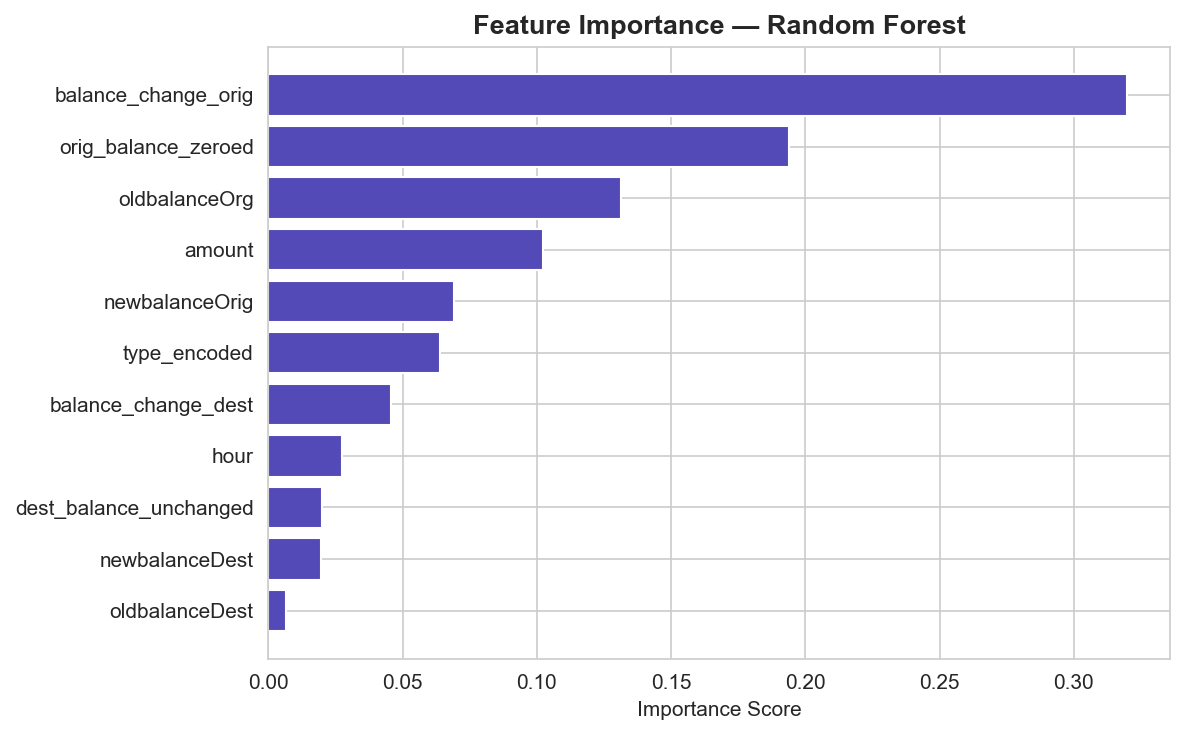

Predictions exported ✓


In [23]:
# Feature importance chart
importance_df = pd.DataFrame({
    'feature'   : features,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance_df['feature'], importance_df['importance'],
        color='#534AB7', edgecolor='white')
ax.set_title('Feature Importance — Random Forest',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.savefig('charts/06_feature_importance.png')
plt.show()

# Add predictions back to test set and export for Power BI
test_results = X_test.copy()
test_results['actual_fraud']  = y_test.values
test_results['predicted_fraud']= y_pred
test_results['fraud_probability'] = y_pred_prob.round(4)
test_results['type'] = le.inverse_transform(test_results['type_encoded'])

test_results.to_csv(r'C:\Users\hp\UPI payment fraud detection & risk dashboard/model_predictions.csv', index=False)
print("Predictions exported ✓")